In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns


In [2]:
train = pd.read_csv('titanic_dataset/train.csv')
test = pd.read_csv('titanic_dataset/test.csv')

In [3]:
women = train.loc[train.Sex == 'female']["Survived"]
rate_women = sum(women)/len(women)

print("% of women who survived:", rate_women)

% of women who survived: 0.7420382165605095


In [ ]:

men = train.loc[train.Sex == 'male']["Survived"]
rate_men = sum(men)/len(men)

print("% of men who survived:", rate_men)



% of men who survived: 0.18890814558058924


#### Version 1

In [57]:

from sklearn.ensemble import RandomForestClassifier

y = train["Survived"]

features = ["Pclass", "Sex", "SibSp", "Parch"]
X = pd.get_dummies(train[features])
X_test = pd.get_dummies(test[features])

model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=1)
model.fit(X, y)
predictions = model.predict(X_test)


In [58]:
output = pd.DataFrame({'PassengerId': test.PassengerId, 'Survived': predictions})
output.to_csv('submission.csv', index=False)
print("Your submission was successfully saved!")

Your submission was successfully saved!


Version 2

In [59]:
## Understanding the data

train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,HasCabin,Group_Size
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208,0.228956,1.787879
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429,0.420397,1.361142
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400,0.000000,1.000000
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200,0.000000,1.000000
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000,0.000000,2.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,1.000000,7.000000


In [60]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   PassengerId    891 non-null    int64  
 1   Survived       891 non-null    int64  
 2   Pclass         891 non-null    int64  
 3   Name           891 non-null    str    
 4   Sex            891 non-null    str    
 5   Age            714 non-null    float64
 6   SibSp          891 non-null    int64  
 7   Parch          891 non-null    int64  
 8   Ticket         891 non-null    str    
 9   Fare           891 non-null    float64
 10  Cabin          204 non-null    str    
 11  Embarked       889 non-null    str    
 12  HasCabin       891 non-null    int64  
 13  Deck           891 non-null    str    
 14  Ticket_Prefix  891 non-null    str    
 15  Group_Size     891 non-null    int64  
dtypes: float64(2), int64(7), str(7)
memory usage: 154.9 KB


| Variable | Definition | Key |
|----------|------------|-----|
| survival | Survival | 0 = No, 1 = Yes |
| pclass | Ticket class | 1 = 1st, 2 = 2nd, 3 = 3rd |
| sex | Sex | |
| Age | Age in years | |
| sibsp | # of siblings / spouses aboard the Titanic | |
| parch | # of parents / children aboard the Titanic | |
| ticket | Ticket number | |
| fare | Passenger fare | |
| cabin | Cabin number | |
| embarked | Port of Embarkation | C = Cherbourg, Q = Queenstown, S = Southampton |

In [61]:
train_num = train[['Age', 'Parch', 'SibSp', 'Fare']]
train_cat = train [['Pclass','Sex', 'Ticket','Cabin', 'Embarked']]

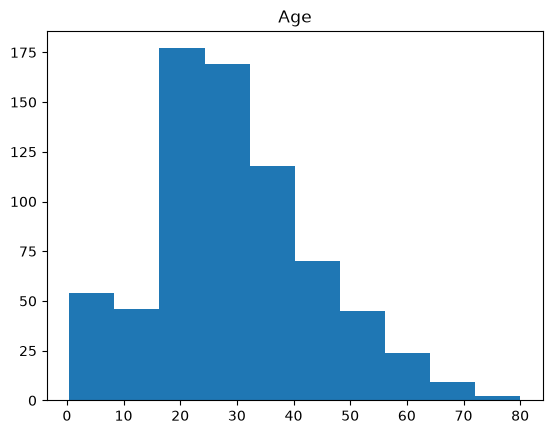

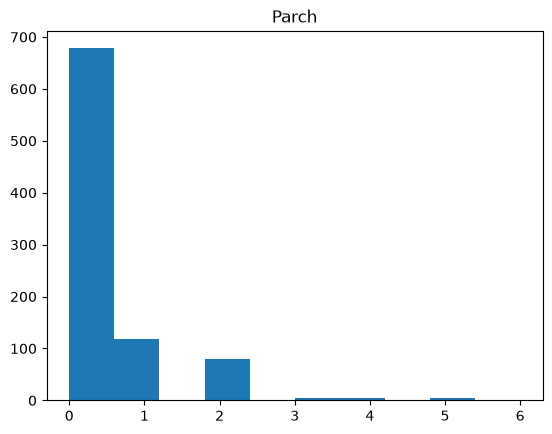

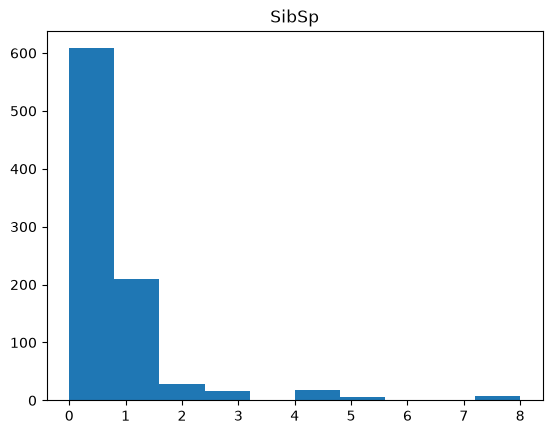

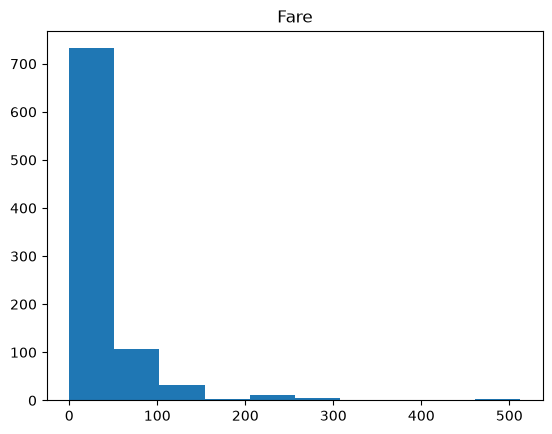

In [62]:
## Data Exploratory
for i in train_num.columns:
    plt.hist(train_num[i])
    plt.title(i)
    plt.show()

Normalize?


In [63]:
for i in train_cat.columns:
    print(train_cat[i].value_counts())

Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Sex
male      577
female    314
Name: count, dtype: int64
Ticket
347082             7
1601               7
CA. 2343           7
3101295            6
CA 2144            6
                  ..
SOTON/OQ 392076    1
211536             1
112053             1
111369             1
370376             1
Name: count, Length: 681, dtype: int64
Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
              ..
E17            1
A24            1
C50            1
B42            1
C148           1
Name: count, Length: 147, dtype: int64
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


In [64]:
train_num.corr

<bound method DataFrame.corr of       Age  Parch  SibSp     Fare
0    22.0      0      1   7.2500
1    38.0      0      1  71.2833
2    26.0      0      0   7.9250
3    35.0      0      1  53.1000
4    35.0      0      0   8.0500
..    ...    ...    ...      ...
886  27.0      0      0  13.0000
887  19.0      0      0  30.0000
888   NaN      2      1  23.4500
889  26.0      0      0  30.0000
890  32.0      0      0   7.7500

[891 rows x 4 columns]>

<Axes: >

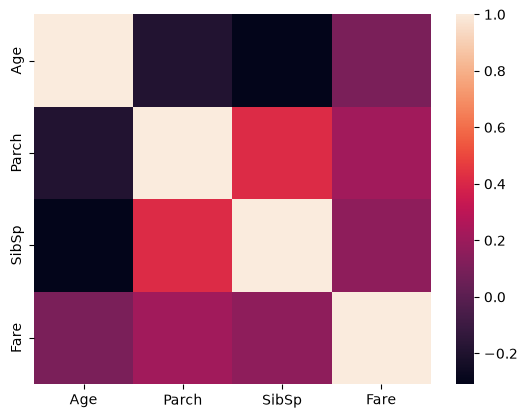

In [65]:
sns.heatmap(train_num.corr())

In [66]:
train['Cabin'].value_counts()

Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
              ..
E17            1
A24            1
C50            1
B42            1
C148           1
Name: count, Length: 147, dtype: int64

In [67]:
train['Ticket'].value_counts()

Ticket
347082             7
1601               7
CA. 2343           7
3101295            6
CA 2144            6
                  ..
SOTON/OQ 392076    1
211536             1
112053             1
111369             1
370376             1
Name: count, Length: 681, dtype: int64

/tmp/ipykernel_22142/1239235346.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['No Cabin recorded', 'Cabin Present'])


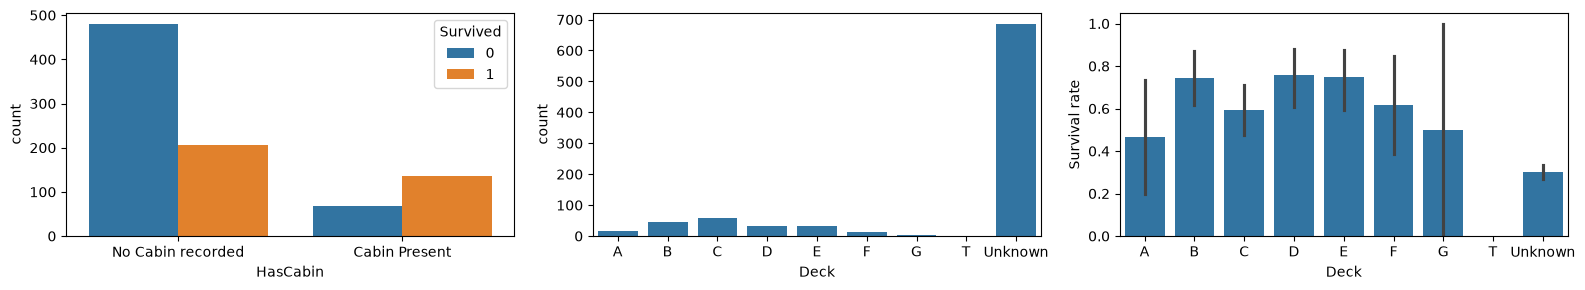

In [68]:
# Feature Engineer

train['HasCabin'] = train['Cabin'].notna().astype(int)
train['Deck'] = train['Cabin'].str[0].fillna('Unknown')

fig, axes = plt.subplots(1, 3, figsize = (16,3))

# 1. HasCabin vs Survived plot

sns.countplot(train, x = 'HasCabin', hue = 'Survived', ax = axes[0])
axes[0].set_xticklabels(['No Cabin recorded', 'Cabin Present'])

# 2. Passerngers per Deck

order = sorted(train['Deck'].unique())
sns.countplot(train, x= 'Deck', order = order, ax = axes[1])

# 3. Survival rate per deck

sns.barplot(train, x = 'Deck', y = 'Survived', order = order , ax = axes[2])
axes[2].set_ylabel('Survival rate')

plt.tight_layout()
plt.show()

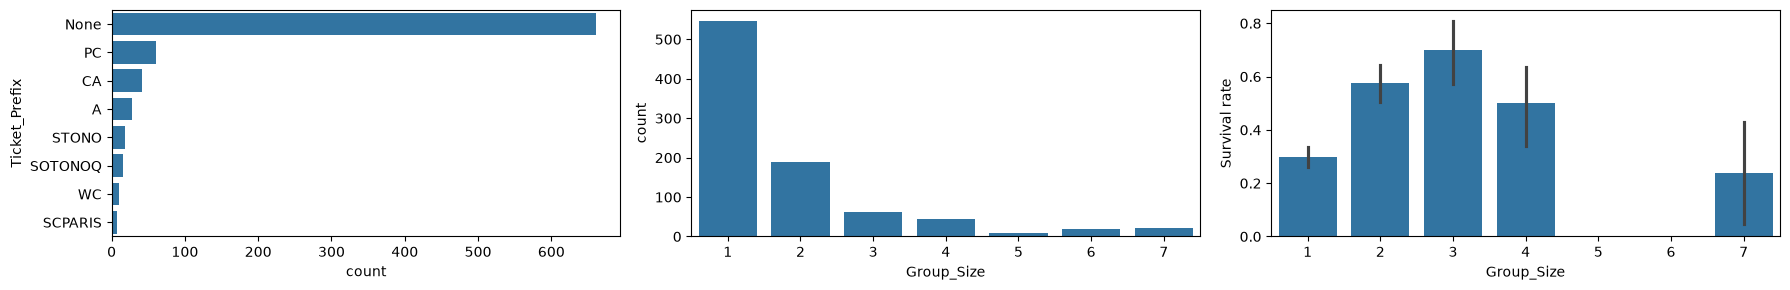

In [69]:
# Feature Engineer
train['Ticket_Prefix'] = (train['Ticket']
                       .str.replace(r'[./]', '', regex=True)
                       .str.extract(r'^([A-Za-z]+)', expand=False)
                       .fillna('None'))
train['Group_Size'] = train.groupby('Ticket')['Ticket'].transform('count')

fig, axes = plt.subplots(1, 3, figsize=(18, 3))

# 1. Most common ticket prefixes
top = train['Ticket_Prefix'].value_counts().head(8).index
sns.countplot(data=train[train['Ticket_Prefix'].isin(top)],
              y='Ticket_Prefix', order=top, ax=axes[0])

# 2. Group size distribution
sns.countplot(data=train, x='Group_Size', ax=axes[1])

# 3. Survival rate by group size
sns.barplot(data=train, x='Group_Size', y='Survived', ax=axes[2])
axes[2].set_ylabel('Survival rate')

plt.tight_layout()
plt.show()

In [70]:
# Class mix of solo vs. grouped travelers
pd.crosstab(train['Group_Size'], train['Pclass'], normalize='index')

Pclass,1,2,3
Group_Size,,,
1,0.177331,0.195612,0.627057
2,0.382979,0.255319,0.361702
3,0.428571,0.380952,0.190476
4,0.454545,0.000000,0.545455
5,0.000000,0.500000,0.500000
6,0.000000,0.000000,1.000000
7,0.000000,0.000000,1.000000


In [71]:
# Does the group-size pattern hold within each class?
train.groupby(['Pclass', 'Group_Size'])['Survived'].agg(['mean', 'count'])


mean  count
Pclass Group_Size                 
1      1           0.474227     97
       2           0.736111     72
       3           0.851852     27
       4           0.700000     20
2      1           0.420561    107
       2           0.562500     48
       3           0.625000     24
       5           0.000000      5
3      1           0.209913    343
       2           0.411765     68
       3           0.500000     12
       4           0.333333     24
       5           0.000000      5
       6           0.000000     18
       7           0.238095     21

<Axes: xlabel='Group_Size', ylabel='Survived'>

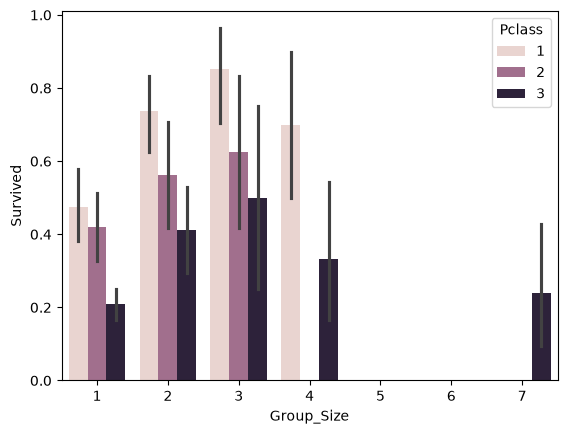

In [72]:
# Visually
sns.barplot(data= train, x='Group_Size', y='Survived', hue='Pclass')

- HasCabin strong usable feature. Binary, no missing values and clearly separates the survival rates
- Deck shows mostly 'Unknown vs known'. The differences among the known decks are mostly within noise because the groups are small. Converting using one hot encoding would only add noise and might lead to overfitting without extra information.
- Confounding awareness. Cabin mostly recorded for 1st-class so HasCabin acts as a proxy for Pclass (and Fare). 
-- To check train.grouby(['Pclass','HasCabin'])['Survived'].mean().

- Group_Size is a useful feature, but the relationship is non-moonotonic. Survival rises from solo to small groups, then drops for large ones.
-- Redundancy with family size. SibSp + Parch + 1 measures similar idea. Compare the two (pd.crosstab(train['Group_Size'], train['SibSp'], train['Parch'] + 1 )). Grroup Size might  be better at capturing and informing since it includes friends, servants travelling on the same ticket, but using both may be redundant
- Confounding awareness. Solo travellers skew towards 3rd which partly explains their lower survival.